# Milestone 1: Data description

Source files: `Data(Final).csv` and `Meteo_Data_ERA5.csv`. PM2.5 primary and PM10 secondary. No trained models. Full future-24-hour labels require complete data. Execute **Restart & Run All** from `notebooks/`.

Pollution dataset: (52603, 3)
Meteorological dataset: (52608, 8)

Missing pollution values:
Date        0
PM10     3967
PM2.5    3965
dtype: int64

Missing meteorological values:
Date                 0
Temperature          0
Relative Humidity    0
Wind-u               0
Wind-v               0
wind_speed           0
wind_direction       0
temperature_C        0
dtype: int64

Duplicate rows: 0
Duplicate timestamps: 7

Humidity values above 100%: 1308

Combined dataset: (52608, 10)
              PM2.5          PM10  temperature_C    wind_speed
count  48631.000000  48629.000000   52608.000000  52608.000000
mean      36.331156     49.607066      16.966929      0.968320
std       37.064664     43.710870       8.477538      0.492785
min        0.760000      0.970000      -8.950000      0.005899
25%       13.330000     22.510000      10.740000      0.610219
50%       22.120000     34.810000      16.555000      0.902128
75%       45.040000     60.790000      23.440000      1.245423
max      338

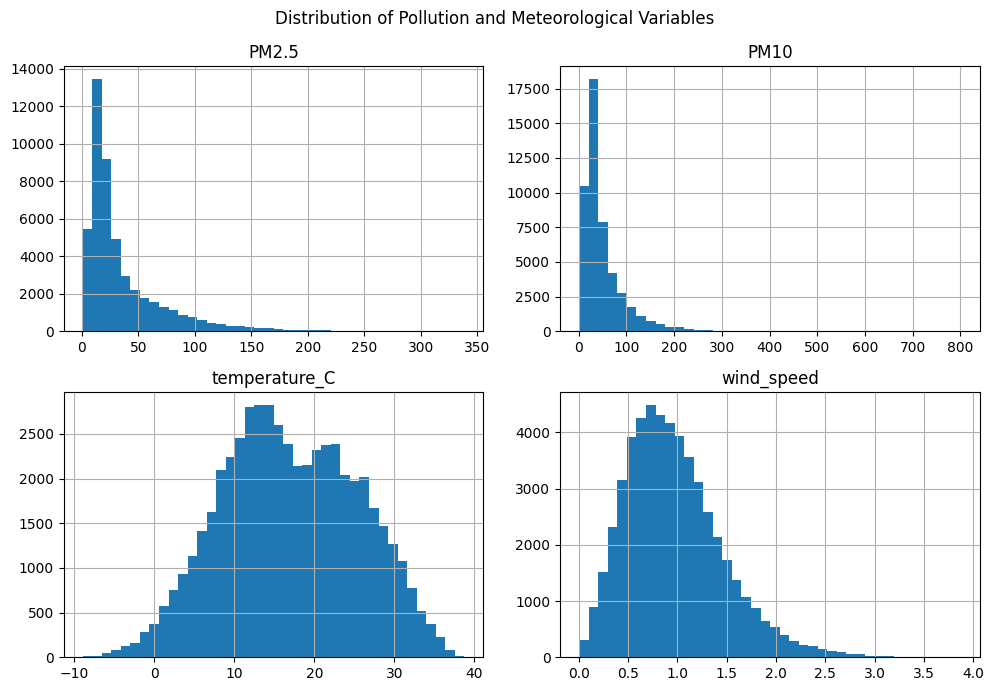

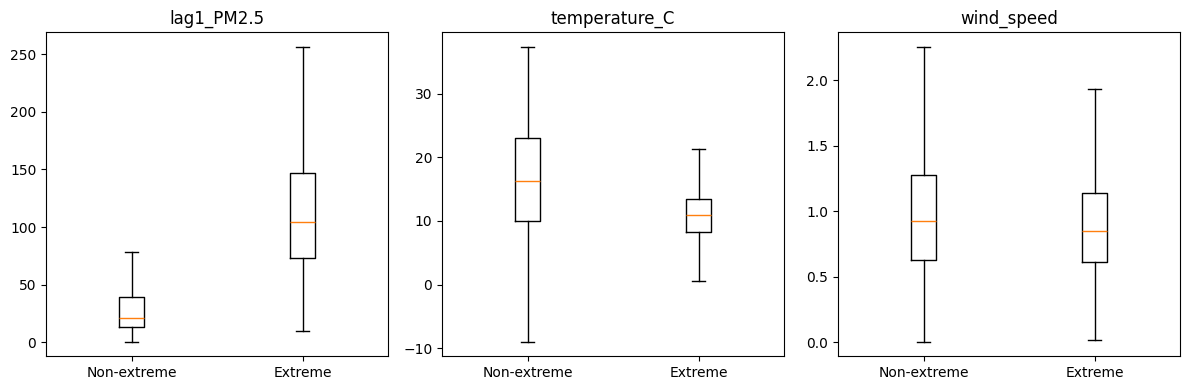

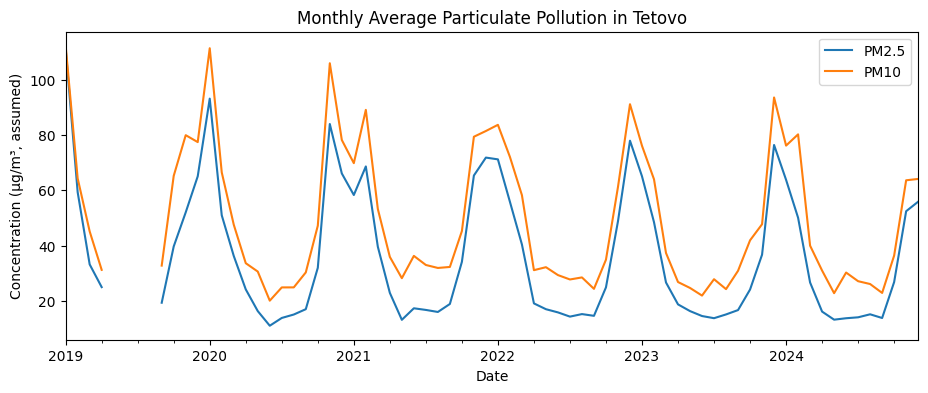

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# 1. Read the datasets
poll = pd.read_csv("Data(Final).csv")
met = pd.read_csv("Meteo_Data_ERA5.csv")

# Convert Date columns
poll["Date"] = pd.to_datetime(poll["Date"], dayfirst=True)
met["Date"] = pd.to_datetime(met["Date"], dayfirst=True)

print("Pollution dataset:", poll.shape)
print("Meteorological dataset:", met.shape)

# 2. Check data quality
print("\nMissing pollution values:")
print(poll.isnull().sum())

print("\nMissing meteorological values:")
print(met.isnull().sum())

print("\nDuplicate rows:", poll.duplicated().sum())
print("Duplicate timestamps:", poll["Date"].duplicated().sum())

print("\nHumidity values above 100%:",
      (met["Relative Humidity"] > 100).sum())

# 3. Combine both datasets
# Average measurements that have the same timestamp
poll = poll.groupby("Date", as_index=False)[["PM2.5", "PM10"]].mean()

df = pd.merge(met, poll, on="Date", how="left")
df = df.sort_values("Date").reset_index(drop=True)

print("\nCombined dataset:", df.shape)
print(df[["PM2.5", "PM10", "temperature_C", "wind_speed"]].describe())

# 4. Split data chronologically
train = df["Date"] < "2023-01-01"
validation = (df["Date"] >= "2023-01-01") & (df["Date"] < "2024-01-01")
test = df["Date"] >= "2024-01-01"

# 5. Calculate the mean pollution during the NEXT 24 hours
for pollutant in ["PM2.5", "PM10"]:

    future = pd.concat(
        [df[pollutant].shift(-i) for i in range(1, 25)],
        axis=1
    )

    # Require all 24 future observations
    df["future24_" + pollutant] = future.mean(
        axis=1
    ).where(future.notna().all(axis=1))

    # Extreme threshold: 90th percentile of training data
    threshold = df.loc[
        train, "future24_" + pollutant
    ].quantile(0.90)

    print("\n", pollutant, "extreme threshold:", round(threshold, 3))

    # Create binary target
    df["extreme_" + pollutant] = (
        df["future24_" + pollutant] > threshold
    ).astype(float)

    # Keep unknown future outcomes as missing
    df.loc[
        df["future24_" + pollutant].isna(),
        "extreme_" + pollutant
    ] = np.nan

# 6. Create historical predictors
df["lag1_PM2.5"] = df["PM2.5"].shift(1)
df["lag1_PM10"] = df["PM10"].shift(1)

df["past24_PM2.5"] = df["PM2.5"].rolling(24).mean()
df["past24_PM10"] = df["PM10"].rolling(24).mean()

# 7. Class distribution and majority-class baseline
for pollutant in ["PM2.5", "PM10"]:

    print("\nCLASS DISTRIBUTION:", pollutant)

    target = "extreme_" + pollutant

    for name, mask in [
        ("Train", train),
        ("Validation", validation),
        ("Test", test)
    ]:
        counts = df.loc[mask, target].value_counts()
        percentages = df.loc[mask, target].value_counts(
            normalize=True
        ) * 100

        baseline = percentages.max()

        print("\n", name)
        print("Counts:\n", counts)
        print("Percentages:\n", percentages.round(2))
        print("Majority-class baseline:", round(baseline, 2), "%")

# 8. Field 8: Compare predictors between classes
features = [
    "lag1_PM2.5",
    "temperature_C",
    "Relative Humidity",
    "wind_speed"
]

signal = df.loc[
    train & df["extreme_PM2.5"].notna()
].groupby("extreme_PM2.5")[features].mean()

signal = signal.T
signal.columns = ["Non-extreme mean", "Extreme mean"]

print("\nFIELD 8: SIGNAL")
print(signal.round(3))

# 9. Figure: Distribution of pollution and weather
df[["PM2.5", "PM10", "temperature_C", "wind_speed"]].hist(
    bins=40,
    figsize=(10, 7)
)

plt.suptitle("Distribution of Pollution and Meteorological Variables")
plt.tight_layout()
plt.show()

# 10. Figure: Signal by future PM2.5 class
fig, axes = plt.subplots(1, 3, figsize=(12, 4))

for ax, feature in zip(
    axes,
    ["lag1_PM2.5", "temperature_C", "wind_speed"]
):
    normal = df.loc[
        train & (df["extreme_PM2.5"] == 0), feature
    ].dropna()

    extreme = df.loc[
        train & (df["extreme_PM2.5"] == 1), feature
    ].dropna()

    ax.boxplot(
        [normal, extreme],
        showfliers=False,
        tick_labels=["Non-extreme", "Extreme"]
    )

    ax.set_title(feature)

plt.tight_layout()
plt.show()

# 11. Monthly pollution pattern
monthly = df.set_index("Date")[["PM2.5", "PM10"]].resample("ME").mean()

monthly.plot(figsize=(11, 4))
plt.title("Monthly Average Particulate Pollution in Tetovo")
plt.ylabel("Concentration (µg/m³, assumed)")
plt.show()